In [1]:
# Data Preparation
# save the data into ./data as car_fuel_efficiency.csv
# run it once to get the data, you dont need to run it again if you already have the data

# data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
# !wget $data -O ../data/car_fuel_efficiency.csv

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


## 2.1 Load and clean the data

In [ ]:
df = pd.read_csv('../data/car_fuel_efficiency.csv')

# normalize column names: lowercase, spaces -> underscores
df.columns = df.columns.str.lower().str.replace(' ', '_')

# normalize string *values* the same way, so 'BMW' and 'Regular Unleaded'
# become 'bmw' and 'regular_unleaded' -- easier to work with, no typos from casing
string_columns = list(df.dtypes[df.dtypes == 'obj'].index)
for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')


# # use this columns only based on the instructions.
# need_columns = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']

# df = df[need_columns]


df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
# quick sanity check on the loaded data: column names, dtypes (all strings show up
# as 'object' since we lowercased them above), and a peek at the first rows
df.columns
# ['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors', 'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight', 'acceleration', 'fuel_efficiency_mpg']

df.dtypes
# model_year               int64
# origin                     str
# fuel_type                  str
# drivetrain                 str
# num_doors                int64
# engine_displacement      int64
# num_cylinders            int64
# horsepower             float64
# vehicle_weight           int64
# acceleration           float64
# fuel_efficiency_mpg    float64

df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
# columns with the missing values
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

## 2.2 The target variable: `fuel_efficiency_mpg`

Text(0.5, 1.0, 'Fuel Efficiency (mpg)')

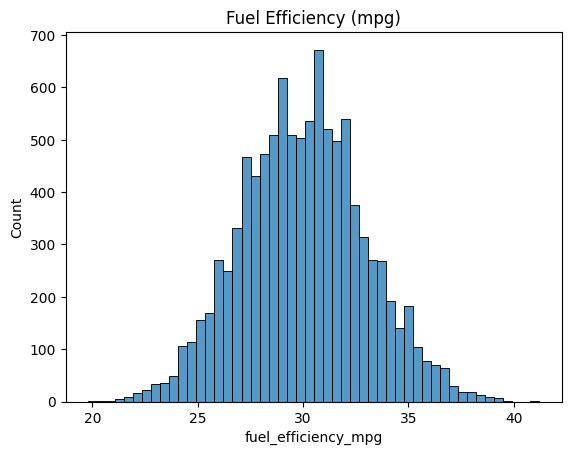

In [6]:
# distribution of the target: right-skewed with a long tail toward higher mpg --
# common for a target like this, and worth keeping in mind since plain linear
# regression assumes roughly symmetric, homoscedastic errors
sns.histplot(df.fuel_efficiency_mpg, bins=50)
plt.title('Fuel Efficiency (mpg)')

In [7]:
df.horsepower.describe()

# you can also use the .median() method
# df.horsepower.median()

count    9123.000000
mean      254.446016
std        22.844613
min       171.000000
25%       239.000000
50%       254.000000
75%       270.000000
max       334.000000
Name: horsepower, dtype: float64

## 2.3 Train / validation / test split

In [8]:
from sklearn.model_selection import train_test_split

df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=42)
# 0.25 of the remaining 80% = 20% of the total -> 60/20/20 split overall
# 0.8(x) = 0.2 -> x = 0.2 / 0.8 = 0.25; this works for me, 0.8 remains when less by 0.2 from the total.


len(df_train), len(df_val), len(df_test)


(6000, 2000, 2000)

In [9]:
# after train_test_split each frame keeps its original (shuffled) row labels;
# reset_index gives each a clean 0..n-1 index so positions line up with y_train/y_val/y_test
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# dropping fuel_efficiency_mpg from the feature frames
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

# drop the target from the feature frames so we can't accidentally train on it
df_train = df_train.drop(columns=['fuel_efficiency_mpg'])
df_val = df_val.drop(columns=['fuel_efficiency_mpg'])
df_test = df_test.drop(columns=['fuel_efficiency_mpg'])


## 2.4 Baseline model

In [10]:
from sklearn.linear_model import LinearRegression  # the actual model: fits weights w0, w to minimize squared error
from sklearn.pipeline import Pipeline  # chains preprocessing + model steps into one object
from sklearn.impute import SimpleImputer  # fills missing values (here: replace NaN with 0)
from sklearn.metrics import root_mean_squared_error  # computes RMSE between true and predicted values

numeric_columns = ['engine_displacement', 'horsepower', 'vehicle_weight', 'acceleration']


# Pipeline chains preprocessing + model into one object: impute missing values first,
# then fit LinearRegression on the result -- calling .fit()/.predict() on the pipeline
# runs both steps in order, so we can't forget to impute on new data later
baseline_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('model', LinearRegression()),
])

baseline_pipeline.fit(df_train[numeric_columns], y_train)

# predict on validation data (never seen during fit) and score with RMSE
y_pred = baseline_pipeline.predict(df_val[numeric_columns])
baseline_rmse = root_mean_squared_error(y_val, y_pred)

print(f'Baseline RMSE: {baseline_rmse:.4f}')


Baseline RMSE: 2.6305


## Feature Engineering: Age of the car based on the max and min year.

In [11]:
from sklearn.compose import ColumnTransformer 

for frame in (df_train, df_val, df_test):
    frame['age'] = frame.model_year.max() - frame['model_year']

numeric_plus_age = numeric_columns + ['age']

preprocess_numeric = ColumnTransformer([
    ('num', SimpleImputer(strategy='constant', fill_value=0), numeric_plus_age),
])

age_pipeline = Pipeline([
    ('preprocess', preprocess_numeric),
    ('model', LinearRegression()),
])

# note we now pass the whole df_train (not df_train[numeric_features]) --
# ColumnTransformer picks out numeric_plus_age itself and ignores the rest
age_pipeline.fit(df_train, y_train)
y_pred = age_pipeline.predict(df_val)
age_rmse = root_mean_squared_error(y_val, y_pred)

print(f'baseline RMSE : {baseline_rmse:.4f}')
print(f'+ age    RMSE : {age_rmse:.4f}')



baseline RMSE : 2.6305
+ age    RMSE : 2.2054


In [12]:
# sanity check -- this is the original `df`, not df_train/df_val/df_test, so it
# still doesn't have the 'age' column added above (that loop only touched the splits)
df.dtypes

model_year               int64
origin                  object
fuel_type               object
drivetrain              object
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [13]:
# reminder of which columns went into the baseline model, before adding
# 'age' and then the categorical columns below
numeric_columns

['engine_displacement', 'horsepower', 'vehicle_weight', 'acceleration']

## Categorical Variables



In [14]:
from sklearn.preprocessing import OneHotEncoder

categorical_columns = ['origin', 'fuel_type', 'drivetrain', 'num_cylinders']

# horsepower and acceleration are the only numeric columns with missing values
# (877 and 264 respectively) -- median imputation for both beats filling with 0,
# so they get their own imputer instead of sharing the constant-0 one below.
numeric_no_missing = ['engine_displacement', 'vehicle_weight', 'age']

preprocess_full = ColumnTransformer([
    ('num', SimpleImputer(strategy='constant', fill_value=0), numeric_no_missing),
    ('horsepower', SimpleImputer(strategy='median'), ['horsepower']),
    ('acceleration', SimpleImputer(strategy='median'), ['acceleration']),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]), categorical_columns),
])

full_pipeline = Pipeline([
    ('preprocess', preprocess_full),
    ('model', LinearRegression()),
])

full_pipeline.fit(df_train, y_train)
y_pred = full_pipeline.predict(df_val)
full_rmse = root_mean_squared_error(y_val, y_pred)

print(f'baseline        RMSE : {baseline_rmse:.4f}')
print(f'+ age           RMSE : {age_rmse:.4f}')
print(f'+ categoricals  RMSE : {full_rmse:.4f}')


baseline        RMSE : 2.6305
+ age           RMSE : 2.2054
+ categoricals  RMSE : 1.6153


In [15]:
# inspect the fitted weights: one-hot encoding categorical_columns turns each
# category into its own 0/1 feature, so the coefficient count grows past the
# 5 original numeric+age features (19 = 5 numeric/age + 14 one-hot category columns)
coefs = full_pipeline.named_steps['model'].coef_
print('number of coefficients:', len(coefs))  
print('max abs coefficient:', np.abs(coefs).max())
print('intercept (w0):', full_pipeline.named_steps['model'].intercept_)

number of coefficients: 19
max abs coefficient: 2.0233132764781385
intercept (w0): 47.839533334767665


## 2.5 Regularization

Plain `LinearRegression` can overfit when features are correlated (here `engine_displacement`,
`horsepower`, `vehicle_weight` all move together) -- the solver can assign large, unstable
weights that cancel each other out. `Ridge` adds an L2 penalty `alpha * sum(w**2)` to the loss,
shrinking the weights toward 0. It's the sklearn equivalent of the manual "add `r` to the
diagonal of `XTX`" trick from the lessons -- `alpha` here plays the same role as `r`.

Same pipeline as the baseline, just swap the model.

In [16]:
from sklearn.linear_model import Ridge  # like LinearRegression, but with an alpha penalty that shrinks large weights

# try several regularization strengths (alpha) and compare validation RMSE +
# the largest resulting coefficient, to see the effect of regularization
for alpha in [0.0, 0.001, 0.01, 0.1, 1, 10, 100]:
    model = Ridge(alpha=alpha) if alpha > 0 else LinearRegression()  # alpha=0 is just plain LinearRegression
    pipeline = Pipeline([
        ('preprocess', preprocess_full),  # reuse the same preprocessing from the categorical step above
        ('model', model),
    ])
    pipeline.fit(df_train, y_train)
    y_pred = pipeline.predict(df_val)
    score = root_mean_squared_error(y_val, y_pred)
    max_coef = np.abs(pipeline.named_steps['model'].coef_).max()
    print(f'alpha={alpha:<8} rmse={score:.4f}  max|coef|={max_coef:.2f}')


alpha=0.0      rmse=1.6153  max|coef|=2.02
alpha=0.001    rmse=1.6153  max|coef|=2.02
alpha=0.01     rmse=1.6153  max|coef|=2.02
alpha=0.1      rmse=1.6153  max|coef|=2.02
alpha=1        rmse=1.6151  max|coef|=2.02
alpha=10       rmse=1.6147  max|coef|=2.00
alpha=100      rmse=1.6163  max|coef|=1.87


## Final Model

In [17]:
# from the sweep above: alpha=10 gave the lowest validation RMSE (1.6226), so that's
# the regularization strength we lock in for the final model
best_alpha = 10

# once alpha is chosen, retrain on train+val combined (more data, better final fit) --
# this is safe now because alpha was picked using only df_val, not df_test
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)
y_full_train = np.concatenate([y_train, y_val])

final_model = LinearRegression() if best_alpha == 0.0 else Ridge(alpha=best_alpha)
final_pipeline = Pipeline([
    ('preprocess', preprocess_full),
    ('model', final_model),
])
final_pipeline.fit(df_full_train, y_full_train)

# df_test was never touched until now -- this is the one true, unbiased estimate
# of how the model performs on unseen data
y_pred = final_pipeline.predict(df_test)
test_rmse = root_mean_squared_error(y_test, y_pred)
test_rmse


1.5911458679823023

## 2.9 Using the model on a single car

In [18]:
# grab one row from the test set as a plain dict, to simulate "a new car we want to price"
car = df_test.iloc[20].to_dict()
car

{'model_year': 1980,
 'origin': 'USA',
 'fuel_type': 'Gasoline',
 'drivetrain': 'Front-wheel drive',
 'num_doors': 4,
 'engine_displacement': 2500,
 'num_cylinders': 7,
 'horsepower': 277.0,
 'vehicle_weight': 4560,
 'acceleration': 20.2,
 'age': 44}

In [19]:
# wrap the single car back into a one-row DataFrame -- the pipeline expects a
# DataFrame with the same columns it was trained on, not a raw dict
df_small = pd.DataFrame([car])
y_pred = final_pipeline.predict(df_small)[0]

predicted_fuel_efficiency_mpg = y_pred
actual_fuel_efficiency_mpg = y_test[20]

print(f'predicted: {predicted_fuel_efficiency_mpg:,.1f} mpg')
print(f'actual:    {actual_fuel_efficiency_mpg:,.1f} mpg')

predicted: 25.7 mpg
actual:    24.6 mpg


In [20]:
# check the model on 20 random rows from the test set, not just index 20
rng = np.random.default_rng(1)
sample_idx = rng.choice(len(df_test), size=20, replace=False)

df_sample = df_test.iloc[sample_idx]
y_sample_pred = final_pipeline.predict(df_sample)
y_sample_actual = y_test[sample_idx]

results = pd.DataFrame({
    'predicted_mpg': y_sample_pred,
    'actual_mpg': y_sample_actual,
    'abs_error': np.abs(y_sample_pred - y_sample_actual),
}, index=sample_idx)
results['pct_error'] = (results['abs_error'] / results['actual_mpg'] * 100).round(2)

results

,predicted_mpg,actual_mpg,abs_error,pct_error
495,36.612355,35.8,0.812355,2.27
1285,31.363339,31.5,0.136661,0.43
55,31.155616,32.3,1.144384,3.54
544,29.352106,29.1,0.252106,0.87
286,33.723651,32.3,1.423651,4.41
1497,29.728210,31.8,2.071790,6.52
937,27.555570,28.5,0.944430,3.31
1987,30.146929,29.9,0.246929,0.83
171,27.873920,30.0,2.126080,7.09
843,28.432723,27.7,0.732723,2.65


## Residual Analysis

Checking the final model's errors on the full test set (not just the 20-row sample) for
patterns that would mean the model is systematically wrong somewhere, rather than just
noisy. Residual = actual - predicted; a well-behaved linear regression should have residuals
that are roughly centered on 0, don't fan out or trend as predictions grow, and look
roughly normal.

In [21]:
# predictions for the whole test set from the final model, and the resulting residuals
y_test_pred = final_pipeline.predict(df_test)
residuals = y_test - y_test_pred

print(f'mean residual : {residuals.mean():.4f}')
print(f'std residual  : {residuals.std():.4f}')
print(f'min / max     : {residuals.min():.4f} / {residuals.max():.4f}')

mean residual : 0.0410
std residual  : 1.5906
min / max     : -4.6882 / 5.4593


Text(0.5, 1.0, 'Distribution of Residuals')

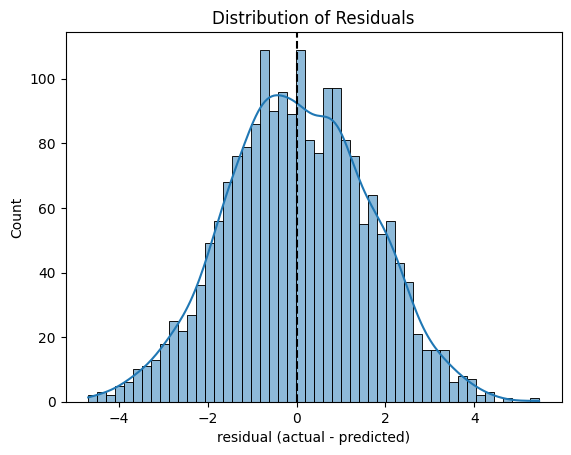

In [22]:
# distribution of residuals -- roughly bell-shaped and centered on 0 is what we want to see
sns.histplot(residuals, bins=50, kde=True)
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('residual (actual - predicted)')
plt.title('Distribution of Residuals')

Text(0.5, 1.0, 'Residuals vs Predicted')

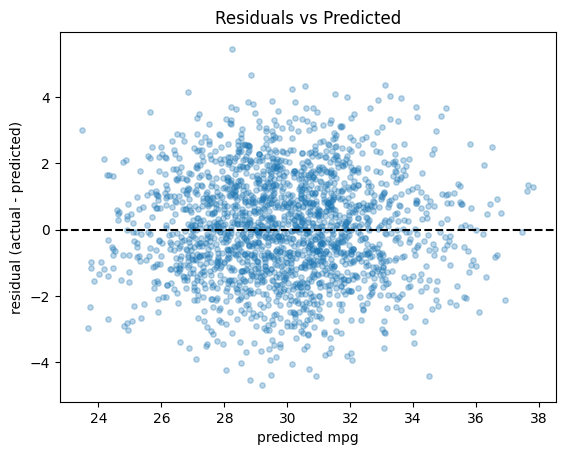

In [23]:
# residuals vs predicted values -- looking for a random scatter around 0.
# a funnel shape would mean errors grow with predicted mpg (heteroscedasticity);
# a curve/trend would mean the model is missing some non-linear relationship
plt.scatter(y_test_pred, residuals, alpha=0.3, s=15)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('predicted mpg')
plt.ylabel('residual (actual - predicted)')
plt.title('Residuals vs Predicted')

Text(0.5, 1.0, 'Q-Q Plot of Residuals')

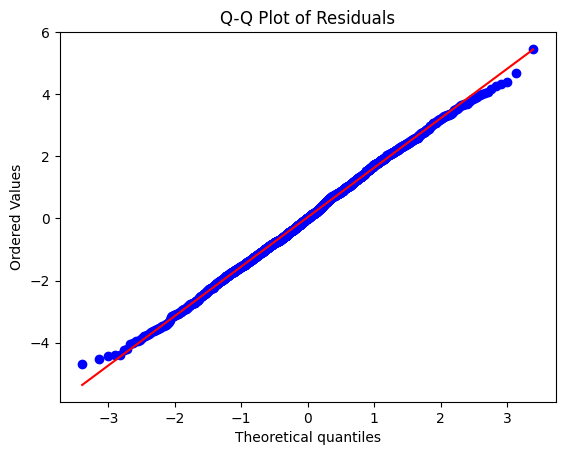

In [24]:
# Q-Q plot: if residuals were perfectly normal, the points would fall on the
# diagonal line. Deviations at the tails mean more extreme errors than a
# normal distribution would predict (fat tails).
import scipy.stats as stats

stats.probplot(residuals, dist='norm', plot=plt)
plt.title('Q-Q Plot of Residuals')

## Summary & Recommendations

### Process, step by step

1. **Load & clean** (2.1) — read the CSV, lowercase/underscore the column names, check for missing values (877 missing `horsepower`, 264 missing `acceleration`).
2. **Target inspection** (2.2) — `fuel_efficiency_mpg` is right-skewed with a long tail.
3. **Split** (2.3) — 60/20/20 train/val/test via two `train_test_split` calls, each with a fixed `random_state`.
4. **Baseline model** (2.4) — plain `LinearRegression` on 4 numeric columns, missing values filled with 0. RMSE 2.6305.
5. **+ age feature** — added `age = model_year.max() - model_year` per split, dropped RMSE to 2.2054.
6. **+ categoricals** — one-hot encoded `origin`, `fuel_type`, `drivetrain`, `num_cylinders`. RMSE dropped to 1.6153 (after switching `horsepower`/`acceleration` imputation from constant-0 to median).
7. **Regularization** (2.5) — swept `Ridge` alpha from 0 to 100; alpha=10 gave the lowest validation RMSE (1.6147).
8. **Final model** — retrained on train+val combined with alpha=10, evaluated once on the untouched test set: RMSE 1.5911.
9. **Single-car & 20-row sample checks** (2.9) — sanity-checked predictions against actuals, including % error per row.
10. **Residual analysis** — mean residual ≈ 0, std ≈ 1.59, histogram/Q-Q/scatter show roughly normal, homoscedastic errors with no strong pattern.

### Is this okay?

Yes, the core methodology is sound:
- **No data leakage** — `alpha` was selected using only the validation set; the test set was touched exactly once, at the very end.
- **Correct order of operations** — impute → encode → fit, all inside `Pipeline`/`ColumnTransformer`, so the same transforms apply consistently to train/val/test and to the single-car example.
- **Regularization was justified and tuned**, not just assumed.
- **Residuals were checked**, not just the RMSE — confirms the linear model's assumptions aren't badly violated.

Two things flagged during review remain as-is and are worth knowing about even though they don't currently affect the numbers:
- `string_columns = list(df.dtypes[df.dtypes == 'str'].index)` in 2.1 never matches (pandas reports string columns as `'object'`, not `'str'`), so the lowercase/underscore normalization silently never runs — `origin` is still `'Europe'`, not `'europe'`. Harmless for `OneHotEncoder`, but the code doesn't do what its comment claims.
- The `age` feature uses each split's own `model_year.max()` as the reference year. It happens to be 2024 in all three splits here, but that's incidental to this particular `random_state`, not guaranteed — a global reference year (computed from `df` before splitting) would be more robust.

### Recommendations

- Fix the `dtype == 'str'` condition to `dtype == 'object'` if consistent lowercase string values are wanted downstream (e.g. for grouping/plotting by category).
- Compute `age` once from `df.model_year.max()` before splitting, and reuse that single reference year across train/val/test.
- Try a **log-transform of the target** (`np.log1p(fuel_efficiency_mpg)`) given its right-skew — linear regression assumptions fit better on a more symmetric target, and it may lower RMSE further.
- Consider **cross-validation** instead of a single train/val split when tuning `alpha`, for a less noisy estimate of the best regularization strength.
- Optionally compare against a non-linear baseline (e.g. `RandomForestRegressor` or `GradientBoostingRegressor`) to see how much headroom the linear model is leaving on the table.